# Archived synthetic reference study

Previous notebook 06, preserved with its original calculated fields and timings. The active [AL1225 study](../06_full_wave_reference_validation.ipynb) replaces this as the main lens example.

# 06 — Full pipeline versus Mie and BEM

The executed synthetic cases show **the calculated fields first**, then complex E/H differences and complete execution times. The sphere uses Mie and BEM references; seven nonspherical lenses use BEM only. Those synthetic calculations use the same x-polarized plane wave, $E_x=1$ V/m, with $\lambda=1$, air outside, sphere index 1.2 and lens index 1.5. No phase or amplitude is fitted.

The full $R_f Q^{-1}TQ R_{z_0}$ pipeline acts at both faces. Its continued open graphs differ from the finite closed Mie/BEM bodies: rims and multiple reflections are absent, and material continues outside the footprint. The reported differences therefore combine physical-model and numerical errors.

The comparison helper constructs an `OpticalSystem` and uses the **spectral** propagation treatment. The stored measurements below are the earlier executed spectral benchmark; API restructuring does not replace them with new timing measurements. Large general geometries without BEM have **no independent accuracy result**.


In [1]:
%matplotlib inline
import os
import platform

import matplotlib.pyplot as plt
import vecdiff_general as optics
from vecdiff_general.propagation.references.benchmarks import illumination
from vecdiff_general.propagation.references.pipeline_comparison import (
    compare_closed_body,
    lens_cases,
    show_comparison,
)

plt.rcParams.update({"image.cmap": "hot", "figure.dpi": 95, "font.size": 9})
source, glass = illumination(wavelength0=1)
settings = dict(
    count=128,
    width=12,
    nodes=18,
    threads=4,
    workers=1,
    mesh_edge=0.20,
    sphere_mesh_level=3,
    boundary_band=0.08,
)
lenses = lens_cases()
results = {}
print(f"{platform.platform()}; {os.cpu_count()} logical CPUs")

macOS-26.5.1-arm64-arm-64bit; 10 logical CPUs


The fixed chart is $128^2$ over $12\lambda$; Fresnel settings are angular limit 0.65, cutoff $10^{-7}$ and retained spectral sine 0.95. Each body receives one full pipeline solve and one cold BEM solve, without calibration or refinement sweeps. Reference preparation includes meshing; complete focal time includes preparation, solve and all 6,561 focal points. All-fields time adds the axial scan, supported meridian and interface diagnostics. Imports and plotting are excluded.

Images use `cmap="hot"` and common intensity limits. The third row shows absolute complex Ex. **White meridional regions are excluded or unsupported by the forward spectra**; their coverage is reported under each case's expandable diagnostics. Differences use all three complex E/H components and the relative L2 norm.

The common plane is the reference on-axis intensity maximum beyond the entire exit-face envelope. An asymmetric lens need not focus on axis. Nonspherical faces remain exact inside their $1.5\lambda$ rim and are smoothly continued outside it; the sphere continuation modifies its outer 5% of radius. BEM's fixed mesh retains discretization uncertainty. [Comparison implementation](../../src/vecdiff_general/propagation/references/pipeline_comparison.py).

## Sphere

Radius λ, index 1.2. Full pipeline, exact Mie and closed-surface BEM.

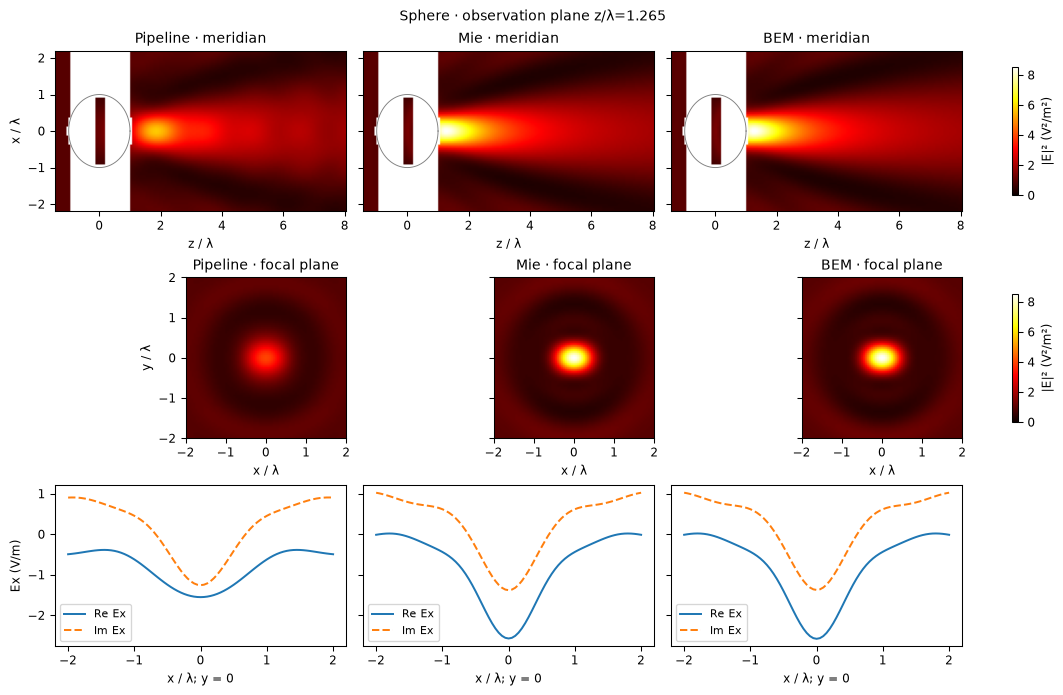

In [2]:
sphere = optics.SphereVolume([0, 0, 0], 1)
sphere_glass = optics.HomogeneousRegion("sphere", optics.Dielectric(1.2))
results["Sphere"] = compare_closed_body(
    "Sphere", sphere, source, sphere_glass, **settings
)
show_comparison(results["Sphere"])

## Plano-convex

Plane entrance; spherical exit with R = −3λ. Vertex spacing 0.8λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

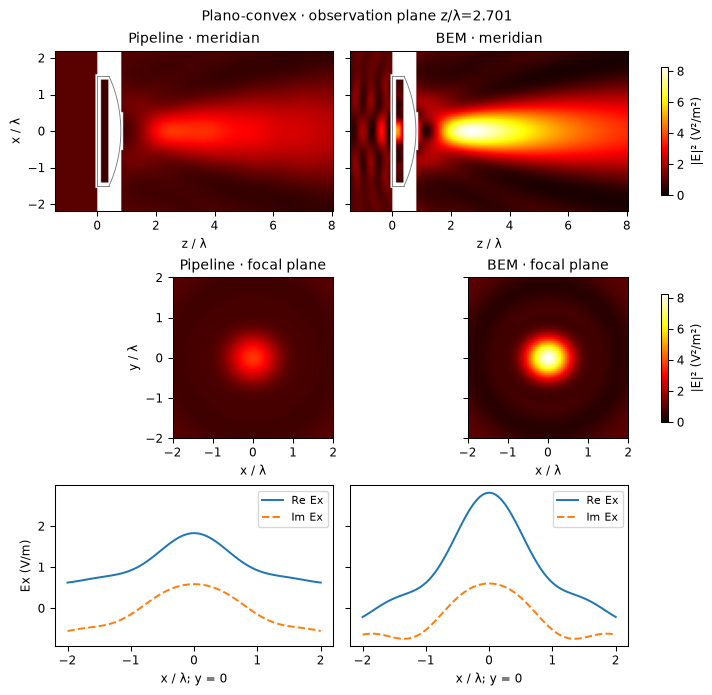

In [3]:
name = "Plano-convex"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## Biconvex

Spherical faces with R = +3λ and −3λ. Vertex spacing 1.2λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

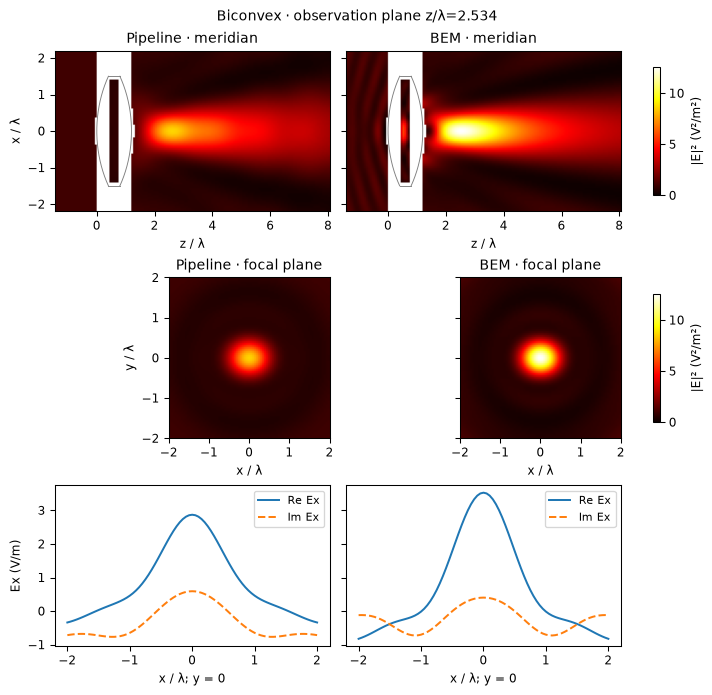

In [4]:
name = "Biconvex"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## Meniscus

Spherical faces with R = +2.2λ and +6λ. Vertex spacing 0.8λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

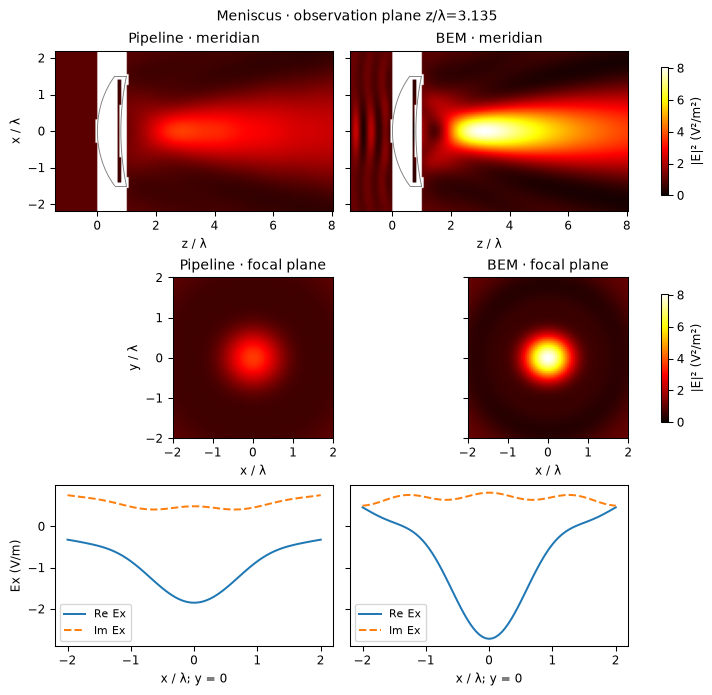

In [5]:
name = "Meniscus"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## Even asphere

Plane entrance; even-aspheric exit with cλ = −1/3, k = −1 and A₄λ³ = −0.015. Spacing 0.8λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

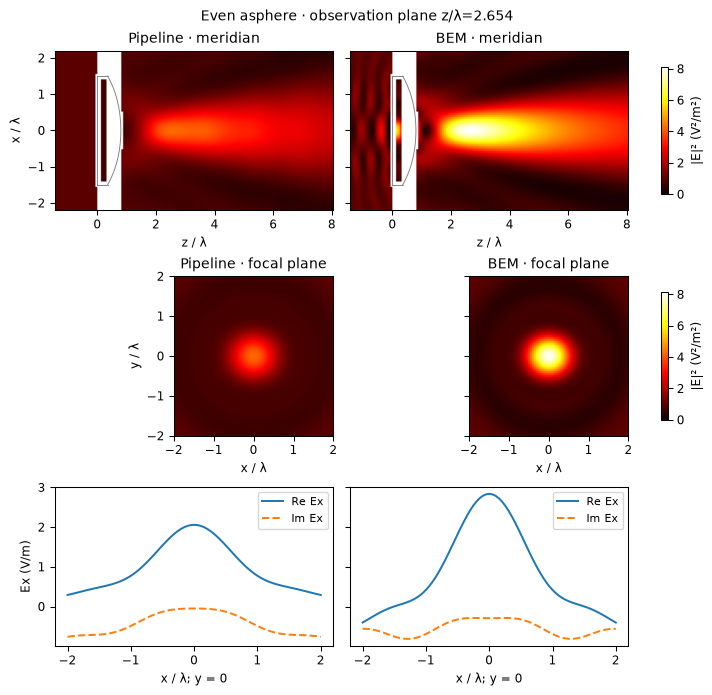

In [6]:
name = "Even asphere"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## Cartesian oval

Plane entrance; oval exit designed for collimated glass-to-air propagation to axial conjugate 6λ. Spacing 0.8λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

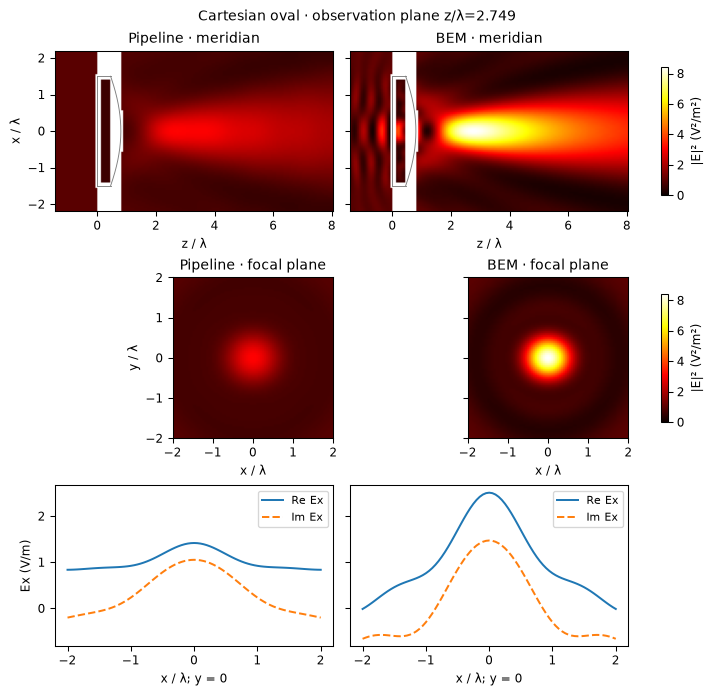

In [7]:
name = "Cartesian oval"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## Astigmatic freeform

Plane entrance; anisotropic quadratic exit with an xy term. Vertex-frame spacing 0.85λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

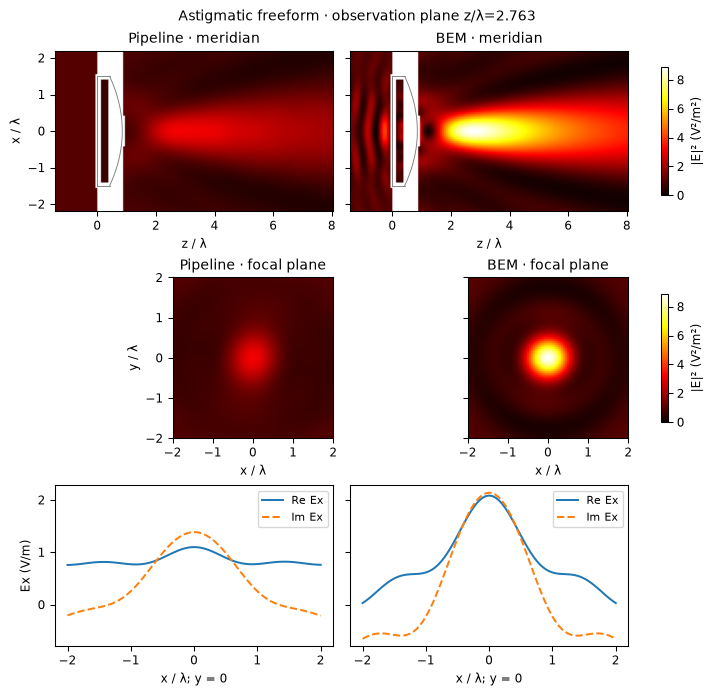

In [8]:
name = "Astigmatic freeform"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## Two freeform faces

An asymmetric quadratic entrance and a decentered quadratic/cubic exit with xy terms. Vertex-frame spacing 1.1λ. Rim radius 1.5λ; index 1.5. Full pipeline versus BEM.

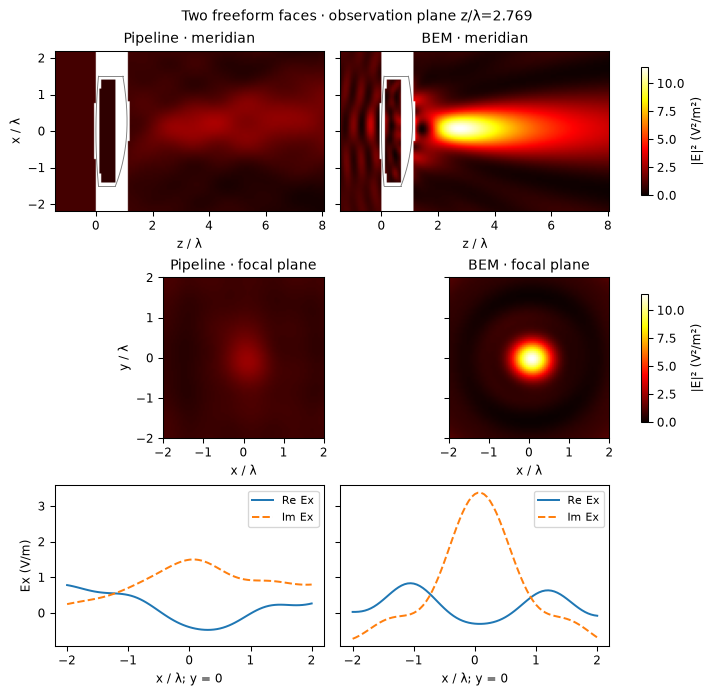

In [9]:
name = "Two freeform faces"
results[name] = compare_closed_body(name, lenses[name], source, glass, **settings)
show_comparison(results[name])

## From three wavelengths to hundreds

Increase $R/\lambda$ through **3, 10, 30 and 100**, with wavelength and indices fixed. Here R is the sphere radius or the lens rim radius; all geometric lengths scale together, preserving each shape. The chart spans $\max(12\lambda,4R)$ and its grid increases to keep pixel spacing at or below $\min(0.4,0.9/(2n_{\max}\,0.95))\lambda$, resolving the configured angular band in both materials. The same angular limits, tolerances and full pipeline are used throughout. Focal maps cover the same $4\lambda\times4\lambda$ region. The axial search spacing stays at or below $0.25\lambda$.

Mie remains an independent sphere reference at every size. BEM keeps $h/\lambda=0.20$ and executes only below its **5,000-unknown dense-solver limit**. Larger BEM entries are explicitly unavailable; we do not enlarge the mesh edge with the body or invent execution times. The general-geometry study therefore measures pipeline scaling at large R, with no independent accuracy claim where BEM cannot run.

Fields appear first, followed by timings and complex-field differences. Each row shares its color limits across methods and preserves the unit-amplitude incident wave. Meridional sampling is a fixed set of comparison points, not a spatially resolved error bound. These open/closed model differences remain present as R increases.

The displayed transverse window is centered on the optical axis at the chosen axial intensity maximum. An asymmetric body can focus off axis, outside this window. Mie-only interface comparisons use exact Q-grid samples; BEM-facet comparisons in the smaller examples use interpolated traces.

In [10]:
from vecdiff_general.propagation.references.pipeline_comparison import (
    show_size_study,
    size_study,
)

size_ratios = (3, 10, 30, 100)
size_results = {}

### Sphere size study

Index 1.2. Pipeline and Mie at every size; BEM wherever the fixed-resolution mesh fits.

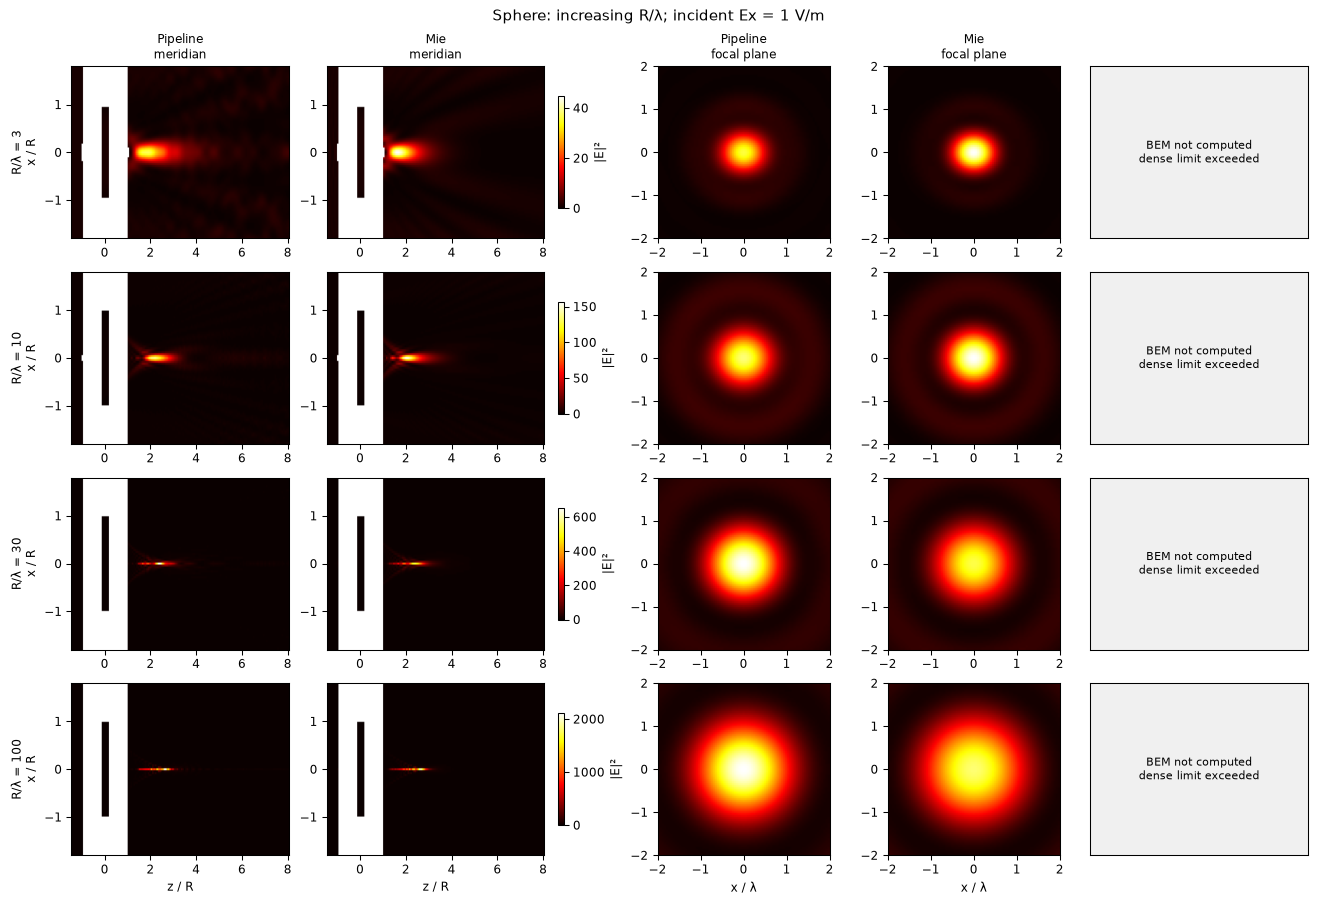

R/λ,Grid,Δ/λ,Pipeline focal (s),Pipeline all fields (s),Mie focal (s),BEM focal (s),Focal E (%),Focal H (%)
3,128,0.09375,1.3,1.497,0.7286,—,26.07,26.08
10,128,0.3125,2.037,2.53,1.105,—,12.35,12.34
30,320,0.375,32.72,38.51,6.411,—,9.869,9.865
100,1024,0.3906,885.2,1001,42.07,—,6.139,6.139


In [11]:
size_results["Sphere"] = size_study("Sphere", sphere, source, sphere_glass, size_ratios)
show_size_study(size_results["Sphere"])

### Cartesian oval size study

Index 1.5. The oval, conjugates, thickness and rim scale together.

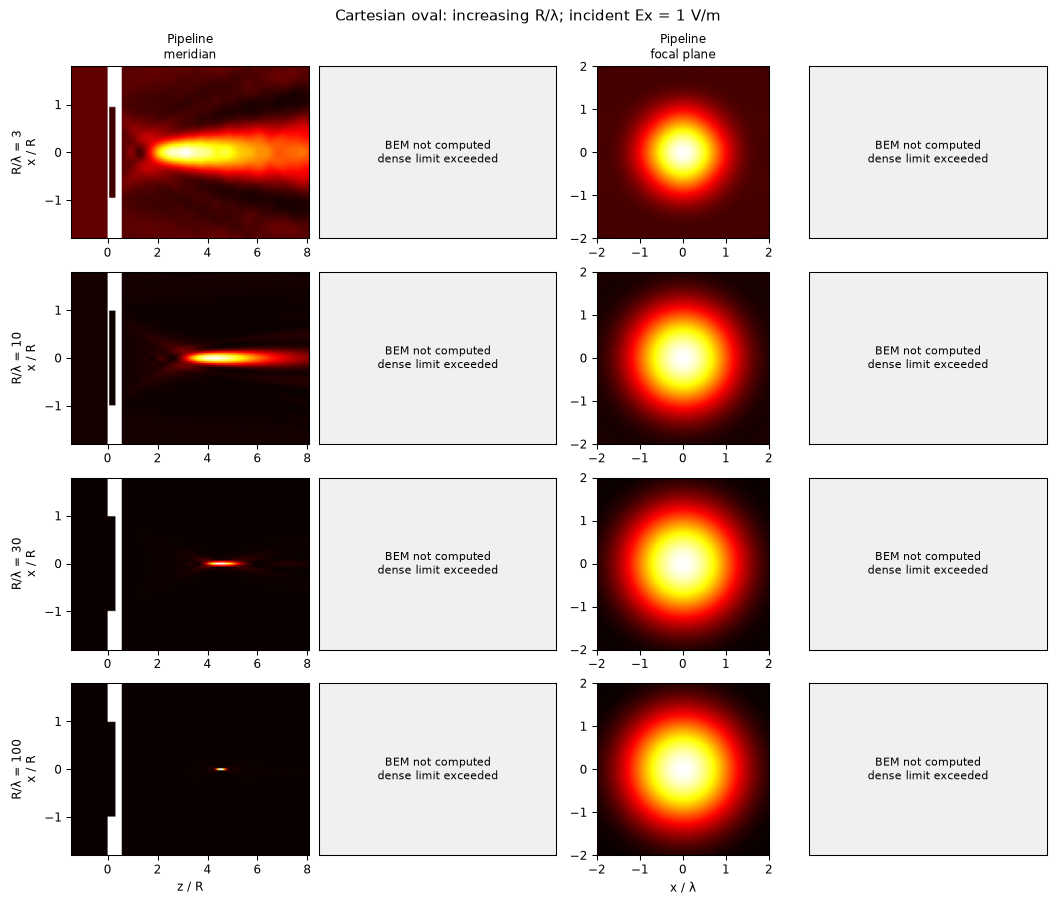

R/λ,Grid,Δ/λ,Pipeline focal (s),Pipeline all fields (s),BEM focal (s),Focal E (%),Focal H (%)
3,128,0.09375,0.0931,0.2061,—,—,—
10,128,0.3125,0.09824,0.4352,—,—,—
30,384,0.3125,0.8164,3.24,—,—,—
100,1280,0.3125,14.22,72.15,—,—,—


R/λ,BEM unknowns,One dense matrix (GiB),BEM computed,Meridian coverage (%),Meridian E (%),Meridian H (%)
3,15792,3.716,False,96.24,—,—
10,≈ 200244,597.5,False,95.93,—,—
30,≈ 1802192,4.84e+04,False,95.91,—,—
100,≈ 20024345,5.975e+06,False,95.88,—,—


In [12]:
name = "Cartesian oval"
size_results[name] = size_study(name, lenses[name], source, glass, size_ratios)
show_size_study(size_results[name])

### Two-freeform-face size study

Index 1.5. Both asymmetric surfaces, their offsets, thickness and rim scale together.

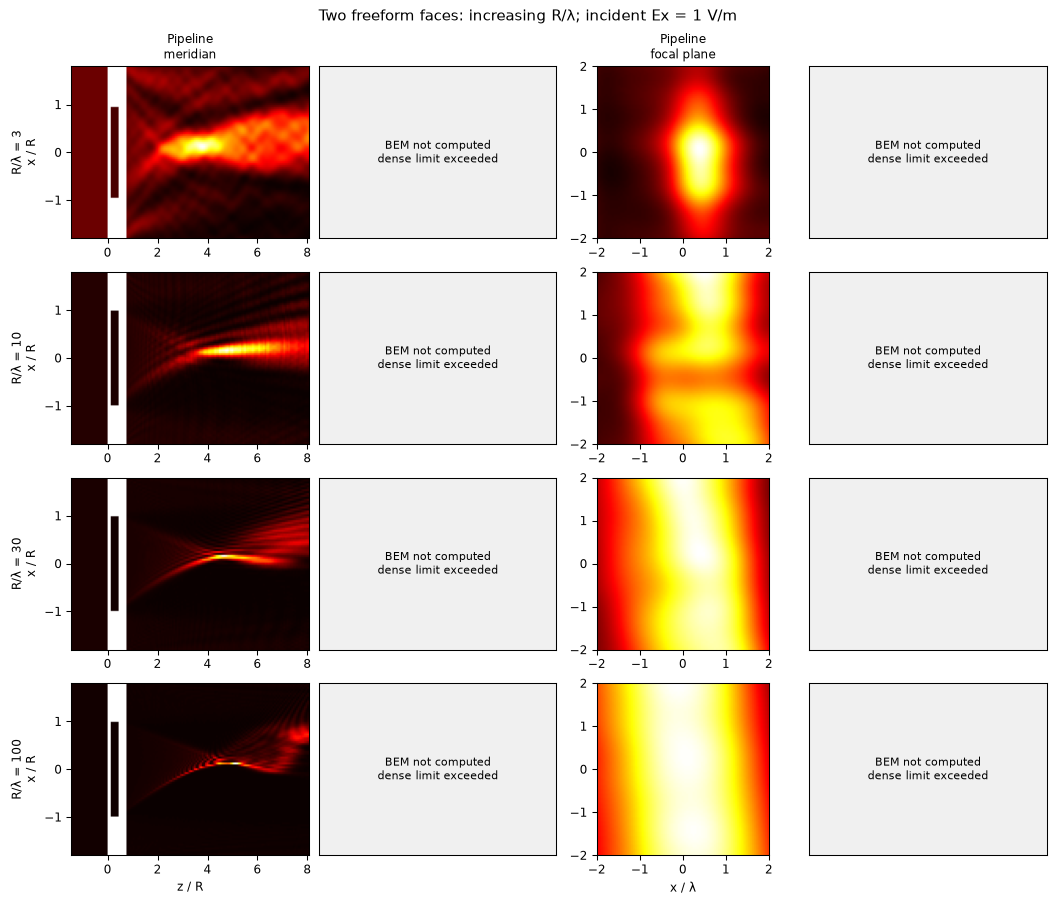

R/λ,Grid,Δ/λ,Pipeline focal (s),Pipeline all fields (s),BEM focal (s),Focal E (%),Focal H (%)
3,128,0.09375,1.826,2.083,—,—,—
10,128,0.3125,2.358,2.992,—,—,—
30,384,0.3125,34.26,38.55,—,—,—
100,1280,0.3125,896.1,1032,—,—,—


R/λ,BEM unknowns,One dense matrix (GiB),BEM computed,Meridian coverage (%),Meridian E (%),Meridian H (%)
3,17802,4.722,False,94.6,—,—
10,≈ 226363,763.5,False,94.12,—,—
30,≈ 2037260,6.185e+04,False,93.95,—,—
100,≈ 22636217,7.635e+06,False,93.9,—,—


In [13]:
name = "Two freeform faces"
size_results[name] = size_study(name, lenses[name], source, glass, size_ratios)
show_size_study(size_results[name])